# SP length:
distribution of SP lengths -> check which is the relevant region to be considered when extracting the peptide and feature – 2 plots, one for training and one for the test set. Might be nice to also add the different folds. 

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

# repository root: go up from the notebook folder until Data_preparation/ is found
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Data_preparation').is_dir())

In [8]:
original_data=pd.read_csv(ROOT / 'Data_preparation' / 'Cleaned_merged_dataset.tsv', sep='\t')
original_data

,Unnamed: 0,class,ID,organism_name,kingdom,length,cleavage_pos,early_trans,fold
0,0,0,Q6YN16,Homo sapiens,Metazoa,418,0,False,4
1,1,0,Q9Y3I1,Homo sapiens,Metazoa,522,0,False,3
2,2,0,P30044,Homo sapiens,Metazoa,214,0,False,5
3,3,0,P07954,Homo sapiens,Metazoa,510,0,False,-1
4,4,0,P21549,Homo sapiens,Metazoa,392,0,False,-1
...,...,...,...,...,...,...,...,...,...
9723,9723,1,Q7M3V1,Chelonus sp. nr. curvimaculatus,Metazoa,246,20,False,5
9724,9724,1,Q8MMH5,Pimpla hypochondriaca,Metazoa,61,20,False,3
9725,9725,1,I6RA76,Scolopendra mutilans,Metazoa,64,18,False,1
9726,9726,1,P0DPU7,Scolopendra dehaani,Metazoa,78,25,False,-1


A questo punto devo estrarre il cleavage site e i fold

In [9]:
pos_df=original_data[original_data['class'] == 1]
pos_df #considero solo le sequenze positive


,Unnamed: 0,class,ID,organism_name,kingdom,length,cleavage_pos,early_trans,fold
8624,8624,1,O43155,Homo sapiens,Metazoa,660,35,False,1
8625,8625,1,O43866,Homo sapiens,Metazoa,347,19,False,2
8626,8626,1,O75629,Homo sapiens,Metazoa,220,31,False,4
8627,8627,1,O94985,Homo sapiens,Metazoa,981,28,False,1
8628,8628,1,P01579,Homo sapiens,Metazoa,166,23,False,4
...,...,...,...,...,...,...,...,...,...
9723,9723,1,Q7M3V1,Chelonus sp. nr. curvimaculatus,Metazoa,246,20,False,5
9724,9724,1,Q8MMH5,Pimpla hypochondriaca,Metazoa,61,20,False,3
9725,9725,1,I6RA76,Scolopendra mutilans,Metazoa,64,18,False,1
9726,9726,1,P0DPU7,Scolopendra dehaani,Metazoa,78,25,False,-1


In [10]:
grouped_SP_fold= pos_df [['cleavage_pos','fold']]
grouped_SP_fold
#inutile lol


,cleavage_pos,fold
8624,35,1
8625,19,2
8626,31,4
8627,28,1
8628,23,4
...,...,...
9723,20,5
9724,20,3
9725,18,1
9726,25,-1


In [11]:
sns.set_theme(
 context='notebook',
 style='whitegrid',
 palette='deep',
 font='sans-serif',
 font_scale=1,
 color_codes=True,
 rc=None
)

## Distribution graph for each fold
It was needed to consider that complexively the test fold had *more entries* than the cross validationb folds taken singularly.
To account for this issue we put  __common_norm== False__ so that the singular distribution are considered on the singular sets and not on the overall amount of entries.

Text(0.5, 1.0, 'Distribution of SP length overall')

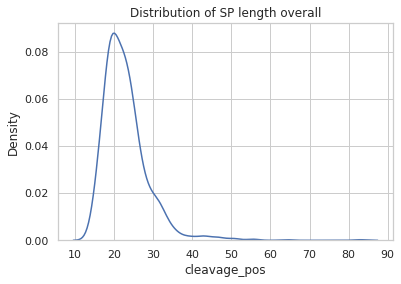

In [12]:
len_dist_overall=sns.kdeplot(data=pos_df, 
            x="cleavage_pos", # variabile che considera per plottare, quindi la lunghezza SP
              palette="rocket"
              )
len_dist_overall.set_title("Distribution of SP length overall")

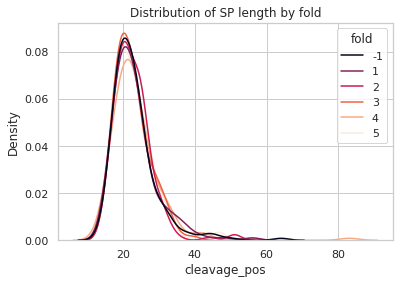

In [13]:
len_vs_fold=sns.kdeplot(data=pos_df, 
            x="cleavage_pos", # variabile che considera per plottare, quindi la lunghezza SP
              hue="fold", # da un colore diverso per ogni fold, quindi 5 colori diversi
              common_norm=False, # non normalizza le distribuzioni, quindi l'area sotto la curva non è 1
              palette="rocket"
              )
len_vs_fold.set_title("Distribution of SP length by fold")
plt.savefig("SP_length_by_fold.svg", format="svg", bbox_inches="tight")

The distribution of the length of the SP is around 20 residues for each of the folds, this is expected. 

# Features vs SP length

## Distribution SP vs kingdom

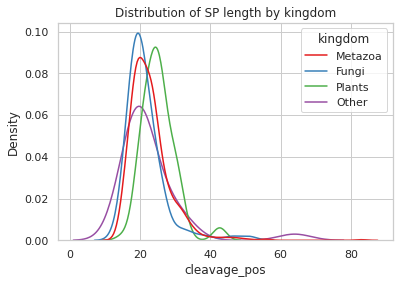

In [14]:
len_vs_kingdom=sns.kdeplot(data=pos_df, 
            x="cleavage_pos", # variabile che considera per plottare, quindi la lunghezza SP
              hue="kingdom", # da un colore diverso per ogni fold, quindi 5 colori diversi
              common_norm=False, # non normalizza le distribuzioni, quindi l'area sotto la curva non è 1
              palette="Set1"
              )
len_vs_kingdom.set_title("Distribution of SP length by kingdom")
plt.savefig("SP_length_by_kingdom.svg", format="svg", bbox_inches="tight")


It can be observed that the distribution of the sp length does not change much amongst the main types of kingdoms considered, except for plants that seems slightly longer. 

## Distribution SP vs protein length


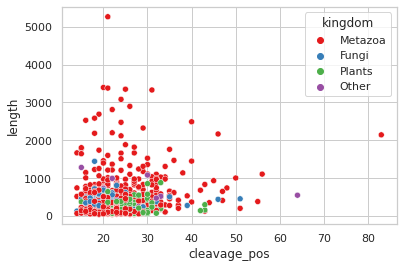

In [15]:
sns.scatterplot(data=pos_df,
                x="cleavage_pos",
                y="length",
                hue="kingdom",
                palette="Set1")
plt.savefig("SP_len_seq_len.svg", format="svg", bbox_inches="tight")